<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/practical_6_by__Tushar_Guleria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Practical 6
Q1. T-Test: Using the teachers' rating data set, does gender affect teaching evaluation rates?

Q2. ANOVA: Using the teachers' rating data set, does beauty score for instructors differ by age?

Q3. Chi-square: Using the teachers' rating data set, is there an association between tenure and gender?

Q4. Correlation: Using the teachers rating dataset, Is teaching evaluation score correlated with beauty score?

# ***Importing Libraries  and data***
import pandas as pd: Think of Pandas as Python's version of Excel. We are loading this tool so we can open and manipulate our spreadsheet.

import scipy.stats as stats: This is a library filled with mathematical formulas. We bring it in so we don't have to calculate the complex statistical tests by hand.

df = pd.read_csv('/content/TeachingRatings.csv'): We are commanding Python to open the "TeachingRatings.csv" file and save all that data inside a variable named df (which stands for DataFrame, meaning data table).

In [ ]:
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('/content/TeachingRatings.csv')

Q1: Independent T-Test (Gender vs. Evaluation)

What you did: You used a T-Test because you are comparing the averages of two separate groups (Males vs. Females) on a continuous numerical score (Evaluation). The code isolates male and female scores and compares their means.

The Result: The p-value is 0.0012. Because this is less than the standard 0.05 threshold, you can tell your teacher that gender does significantly affect teaching evaluation rates in this dataset.

*in code*:

male_eval = df[df['gender'] == 'male']['eval']: We are filtering the data table to look only at the rows where the gender is "male", and then scooping up just their evaluation scores into a single list.

female_eval = df[df['gender'] == 'female']['eval']: We do the exact same thing, but scoop up the evaluation scores for the "female" rows.

stats.ttest_ind(male_eval, female_eval): We feed these two separate lists into the T-test calculator. It mathematically compares the averages of both lists to see if the difference between them is significant.


In [ ]:
# --- Q1: T-Test (Gender vs. Evaluation) ---
# Separating the evaluation scores for men and women
male_eval = df[df['gender'] == 'male']['eval']
female_eval = df[df['gender'] == 'female']['eval']
t_stat, p_val1 = stats.ttest_ind(male_eval, female_eval)
corr_matrix = df[['eval', 'beauty', 'age']].corr()

Q2: One-Way ANOVA (Age vs. Beauty)

What you did: You used an ANOVA because you want to compare averages across more than two groups. Since "age" is a continuous number, the code categorizes teachers into three age brackets (Young, Mid, Senior) so the ANOVA can properly compare their beauty scores.

The Result: The p-value is 0.0000 (less than 0.05). You can confidently state that beauty scores do significantly differ depending on the instructor's age bracket.

*in code:*

df['age_group'] = pd.cut(...): ANOVA requires distinct categories, but our "age" column is just a list of exact numbers (like 36, 59, 41). This line slices those exact ages into three buckets: "Young" (under 40), "Mid" (40 to 55), and "Senior" (over 55), creating a brand new column in our data called age_group.

young = ..., mid = ..., senior = ...: Just like we did with gender, we are creating three separate lists, scooping up the beauty scores for each specific age bucket.

stats.f_oneway(young, mid, senior): We feed all three lists into the ANOVA calculator to check if the average beauty scores are vastly different across the three age groups.

In [ ]:
# --- Q2: ANOVA (Age vs. Beauty) ---
# ANOVA requires categories. We split 'age' into 3 groups: Young (<40), Mid (40-55), Senior (>55)
df['age_group'] = pd.cut(df['age'], bins=[0, 40, 55, 100], labels=['Young', 'Mid', 'Senior'])
young = df[df['age_group'] == 'Young']['beauty']
mid = df[df['age_group'] == 'Mid']['beauty']
senior = df[df['age_group'] == 'Senior']['beauty']
f_stat, p_val2 = stats.f_oneway(young, mid, senior)

Q3: Chi-Square Test (Tenure vs. Gender)

What you did: You used a Chi-Square test because both variables are categorical (Gender is Male/Female; Tenure is Yes/No). The code builds a simple table counting the intersections of these categories and tests if they are linked.

The Result: The p-value is 0.1374. Because this is greater than 0.05, you can explain that there is no statistically significant association between a teacher's gender and whether they have tenure.

*in code:*


pd.crosstab(df['tenure'], df['gender']): This creates a simple tally table. It counts the overlaps and outputs a 2x2 grid showing exactly how many males have tenure, males without tenure, females with tenure, and females without tenure.

stats.chi2_contingency(...): We feed that tally table into the Chi-Square calculator. It checks if the distribution of those counts is expected, or if one gender is getting tenured at a disproportionately high or low rate.

In [ ]:
# --- Q3: Chi-square (Tenure vs. Gender) ---
# Creating a cross-tabulation table to count how many men/women have tenure
contingency_table = pd.crosstab(df['tenure'], df['gender'])
chi2, p_val3, dof, expected = stats.chi2_contingency(contingency_table)

Q4: Pearson Correlation (Evaluation vs. Beauty)

What you did: You used a Pearson Correlation because you are looking at the relationship between two continuous numerical variables to see if they move together.

The Result: The p-value is 0.0000 (less than 0.05). This proves there is a statistically significant correlation between a teacher's beauty score and their teaching evaluation score.

*in code:*

stats.pearsonr(df['eval'], df['beauty']): We feed the entire column of evaluation scores and the entire column of beauty scores into the correlation calculator. It checks if there is a trend—for example, if a teacher's beauty score is high, does their evaluation score tend to be high as well?

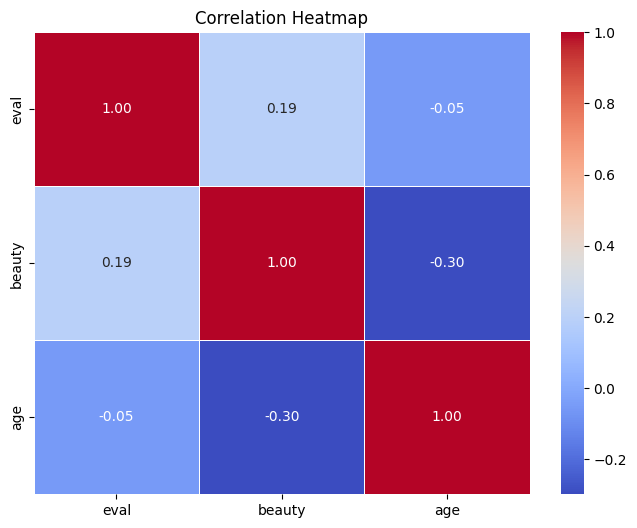

In [ ]:
# --- Q4: Correlation (Evaluation vs. Beauty) ---
# Checking if evaluation scores go up or down as beauty scores change
corr, p_val4 = stats.pearsonr(df['eval'], df['beauty'])
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

print(..., round(p_val, 4)): The code calculates a lot of background math, but we only really care about the "p-value" (the final score that tells us if the test succeeded). These lines simply print the p-value on your screen, rounding it to 4 decimal places so it is easy to read.

In [ ]:
# --- Print Results ---
print("Q1 T-Test p-value:", round(p_val1, 4))
print("Q2 ANOVA p-value:", round(p_val2, 4))
print("Q3 Chi-Square p-value:", round(p_val3, 4))
print("Q4 Correlation p-value:", round(p_val4, 4))

Q1 T-Test p-value: 0.0012
Q2 ANOVA p-value: 0.0
Q3 Chi-Square p-value: 0.1374
Q4 Correlation p-value: 0.0
